In [2]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt

In [7]:
data = pd.read_csv('./datasets/digit-recognizer/train.csv')
data.head()
test_data = pd.read_csv('./datasets/digit-recognizer/test.csv')

In [4]:
from torch.utils.data import Dataset, DataLoader

In [5]:
class DigitDataset(Dataset):
    def __init__(self, data):
        self.data = data

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        image = self.data.iloc[idx, 1:].values.astype(np.float32).reshape(28, 28)
        label = self.data.iloc[idx, 0]
        return image, label

In [8]:
data = DigitDataset(data)
train_loader = DataLoader(data, batch_size=64, shuffle=True)
test_loader = DataLoader(DigitDataset(test_data), batch_size=64, shuffle=False)

In [13]:
print(train_loader)
for data, label in train_loader:
    print(data.shape, label.shape)
    break

torch.Size([64, 28, 28]) torch.Size([64])


In [9]:
input_size = 784
output_size = 10
layer_1 = 128
layer_2= 64
layer_3 = 32
learning_rate = 0.001

In [10]:
import torch.nn as nn
import torch.nn.functional as F

In [18]:
class DenseNet(nn.Module):
    def __init__(self):
        super(DenseNet, self).__init__()
        self.fc1 = nn.Linear(input_size, layer_1)
        self.fc2 = nn.Linear(layer_1, layer_2)
        self.fc3 = nn.Linear(layer_2, layer_3)
        self.fc4 = nn.Linear(layer_3, output_size)

    def forward(self, x):
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = F.relu(self.fc3(x))
        x = F.softmax(self.fc4(x))
        return x

In [15]:
import torch.optim as optim
import torch
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = DenseNet().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=learning_rate)

def train(model, train_loader, criterion, optimizer, device):
    model.train()
    total_loss = 0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images = images.view(images.size(0), -1).to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * images.size(0)
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    avg_loss = total_loss / len(train_loader.dataset)
    accuracy = correct / total
    return avg_loss, accuracy

# def evaluate(model, test_loader, criterion, device):


Epoch [1/10], Loss: 0.3464, Accuracy: 0.8989
Epoch [2/10], Loss: 0.1432, Accuracy: 0.9568
Epoch [3/10], Loss: 0.1100, Accuracy: 0.9660
Epoch [4/10], Loss: 0.0867, Accuracy: 0.9736
Epoch [5/10], Loss: 0.0783, Accuracy: 0.9759
Epoch [6/10], Loss: 0.0676, Accuracy: 0.9787
Epoch [7/10], Loss: 0.0557, Accuracy: 0.9826
Epoch [8/10], Loss: 0.0552, Accuracy: 0.9827
Epoch [9/10], Loss: 0.0502, Accuracy: 0.9843
Epoch [10/10], Loss: 0.0465, Accuracy: 0.9859


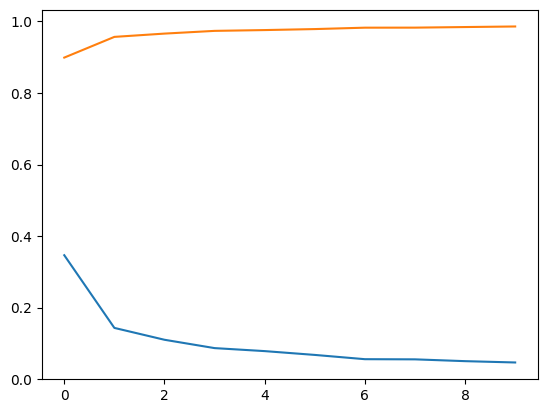

In [16]:
train_losses = []
train_accuracies = []


num_epochs = 10
for epoch in range(num_epochs):
    train_loss, train_accuracy = train(model, train_loader, criterion, optimizer, device)
    train_losses.append(train_loss)
    train_accuracies.append(train_accuracy)

    print(f'Epoch [{epoch+1}/{num_epochs}], Loss: {train_loss:.4f}, Accuracy: {train_accuracy:.4f}')

plt.plot(train_losses, label='Training Loss')
plt.plot(train_accuracies, label='Training Accuracy')
